# C1 · LLM résumé evaluation and intersectional disparities

**Case:** An, Huang, Lin & Tai (2025), *Measuring gender and racial biases in large language models: Intersectional evidence from automated resume evaluation*, PNAS Nexus.  
**Paper:** https://doi.org/10.1093/pnasnexus/pgaf089  
**Original author data and code:** https://osf.io/4dahv/  
**Evidence:** author-released Stata analysis files, with a descriptive Python audit. This notebook does not reproduce the paper's full fixed-effects/clustered inference.  
**Full guided lesson:** about 75–100 minutes. The class uses selected core sections.  
**Learning goal:** distinguish a model score, a hypothetical shortlist, and an unavailable job-performance target.

### How students use this notebook

Run cells in order. Pause at every **Student task** and record your expectation before showing the worked answer. Name the numerator, denominator, unit and decision rule beside each reported number. The raw folder preserves inputs; the processed folder holds documented teaching tables. Rebuild processed data with `python scripts/process_data.py` from the package root. The source manifest records download versions and distinguishes generated inputs.

For the 150-minute lesson, your team completes the core sections assigned in `INSTRUCTOR_GUIDE.md`. The full notebook takes longer and can support self-study. Part 2 is deliberately unfinished. Running Part 1 supplies a baseline; it does not constitute a final project. Use only data whose provenance and permitted use you can explain.

**Instructor / course:** ____________________  
**Student / team / date:** ____________________

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "data/DATA_MANIFEST.json").exists())
sys.path.insert(0, str(ROOT / "src"))
from fairness_lab import (load_table, audit_table, confusion_counts, rates, rate_gaps,
    wilson_interval, bootstrap_mean_interval, paired_summary, matching_scores, alleged_age_veto)
SEED=42
pd.set_option("display.max_columns",25)
pd.set_option("display.max_rows",25)
pd.set_option("display.float_format",lambda x:f"{x:.4f}")
plt.rcParams.update({"figure.figsize":(9,4.5),"axes.spines.top":False,
    "axes.spines.right":False,"font.size":11})
%matplotlib inline
print("Local data only. No API key, paid model, or live LLM is needed.")

Local data only. No API key, paid model, or live LLM is needed.


## Part 1 — Guided theory and practice

### Dataset, features and target: an explicit schema

| Role | Source or teaching fields | Meaning and audit concern |
|---|---|---|
| Observation | `record_id` | Added local row ID. It cannot join separate files or establish controlled pairs. |
| Audit cues | `igender`, `iethnicity`, decoded `gender_cue`, `race_cue` | Randomized female/male and black/white name cues. They describe the experiment, not actual identities. |
| Context | `iposition`, `istate`, `last_work_title` | Occupation, state and nominal prior job category. Context affects both scoring and comparison. |
| Résumé information | `worknum`, `edunum`, `skillnum`, `highest_degree` | Counts of work, education and skill entries, plus a degree category. Counts do not directly measure skill quality. |
| Derived résumé controls | work/education dates, durations and description length | Author-engineered controls. Check definitions and source units before interpreting them. |
| Observed model output | `score_gpt35`, then four other score columns in a separate file | Assessment score on 0–100. These are the audit outcomes, not true candidate ability or a calibrated hiring probability. |
| Hypothetical decision | `selected = score ≥80` | A disclosed classroom shortlist rule. It was not an observed hiring decision. |
| Missing validation target | job success, independent qualification assessment | Not supplied. TPR/FPR/FNR for actual suitability cannot be estimated here. |

The release has five `.dta` files. The baseline and heterogeneity tables each have 332,895 records. The four-model table has 332,257. The bootstrap file has 3,000 **stored estimates**, and the threshold-magnitude file has 36 **stored effects**. They are not five interchangeable applicant tables. The baseline has one missing score. The approximate 361,000-résumé headline describes a larger generated corpus than these released analysis tables.

### Raw loader and engineering checkpoint

**Student task:** Which numeric columns are categories? Why would using `iethnicity=2` as twice `iethnicity=1` be wrong? The source codes are nominal. Keep them and their embedded labels. Date strings require a documented encoding for adjusted modelling. The following reads raw data with categorical conversion disabled, then checks the processed cohort. It does not modify the source.

In [2]:
raw_path=ROOT/"data/raw/01_an_resume/data_gpt35_baseline.dta"
with pd.io.stata.StataReader(raw_path,convert_categoricals=False) as reader:
    raw=reader.read()
    raw_labels=reader.value_labels()
    variable_labels=reader.variable_labels()
display(pd.Series({k:variable_labels.get(k,"") for k in
    ["score_gpt35","worknum","edunum","skillnum","highest_degree","igender","iethnicity"]},name="Embedded variable labels"))
processed=load_table("01_an_resume","data_gpt35_baseline.csv.gz")
assert len(raw)==len(processed)==332895
assert raw.score_gpt35.isna().sum()==processed.score_gpt35.isna().sum()==1
assert set(raw.igender.dropna())=={1,2} and set(raw.iethnicity.dropna())=={1,2}
assert not {"job_success","qualified","performance_y"}.intersection(processed.columns)
print("Raw rows retained; codes preserved; one missing score remains missing.")

<ipython-input-2-e96ff66274ca>:4: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  raw_labels=reader.value_labels()


score_gpt35       Score_Gpt35_With_Name
worknum                        Work Num
edunum                          Edu Num
skillnum                      Skill Num
highest_degree              Edu_1_Level
igender                          Gender
iethnicity                    Ethnicity
Name: Embedded variable labels, dtype: object

Raw rows retained; codes preserved; one missing score remains missing.


### 1.1 Paper in focus and evidence boundaries

The study randomized demographic name cues in fictitious entry-level résumés and evaluated five model snapshots. Its contribution is a controlled audit of assessment scores, including gender-by-race comparisons. This lesson uses the authors’ released analysis files rather than contacting those models. The article describes about 361,000 generated résumés; the released GPT-3.5 analysis table contains **332,895 rows**, one with a missing score. Do not silently replace one sample size with the other.

Our score summaries are descriptive teaching analyses. The original Stata code uses additional controls, fixed effects and clustered standard errors. A grouped mean or bootstrap below is not the published regression coefficient or its p-value. Neither these old model snapshots nor this résumé distribution establish the behaviour of a current deployment.

### 1.2 Load the data and inspect the embedded coding

`gender_cue` and `race_cue` describe the assigned cue categories, not the true identities of real applicants. The source uses female/male and black/white categories. Keep their restricted coverage visible. `record_id` is a local row identifier; it does not prove that rows in separate files refer to the same generated résumé.

In [3]:
released=load_table("01_an_resume","data_gpt35_baseline.csv.gz")
dictionary=json.loads((ROOT/"data/processed/01_an_resume/stata_dictionary.json").read_text())
display(pd.Series(dictionary["data_gpt35_baseline.dta"]["value_labels"]["igender"],name="source gender codes"))
display(pd.Series(dictionary["data_gpt35_baseline.dta"]["value_labels"]["iethnicity"],name="source race codes"))
print("Released rows:",len(released),"Missing GPT-3.5 scores:",int(released.score_gpt35.isna().sum()))
data=released.dropna(subset=["score_gpt35","gender_cue","race_cue"]).copy()
assert data.score_gpt35.between(0,100).all()
print("Complete score rows for this audit:",len(data))
display(data[["record_id","occupation","gender_cue","race_cue","score_gpt35","worknum","skillnum"]].head())

1    female
2      male
Name: source gender codes, dtype: object

1    black
2    white
Name: source race codes, dtype: object

Released rows: 332895 Missing GPT-3.5 scores: 1
Complete score rows for this audit: 332894


,record_id,occupation,gender_cue,race_cue,score_gpt35,worknum,skillnum
0,0,administrative assistant,female,white,70.0000,3,1
1,1,administrative assistant,female,white,70.0000,3,5
2,2,administrative assistant,female,white,75.0000,4,5
3,3,administrative assistant,female,white,65.0000,1,3
4,4,administrative assistant,female,white,80.0000,3,7


### 1.3 First visualize support and scores

**Student task:** Predict why a marginal “female vs male” mean might miss an important race-by-gender result. Count each intersection before calculating its mean. Which category is the reference, and what is the sign of your comparison?

The next table shows n, the mean, median and spread. The histogram uses the released score scale, not a probability scale. Narrow or rounded score distributions can cause many decisions to change together at a threshold.

,n,mean,median,sd
audit_group,,,,
black / female,83159,74.8511,75.0000,7.8061
black / male,83381,74.1644,75.0000,7.9272
white / female,83173,74.6673,75.0000,7.8652
white / male,83181,74.4657,75.0000,7.7954


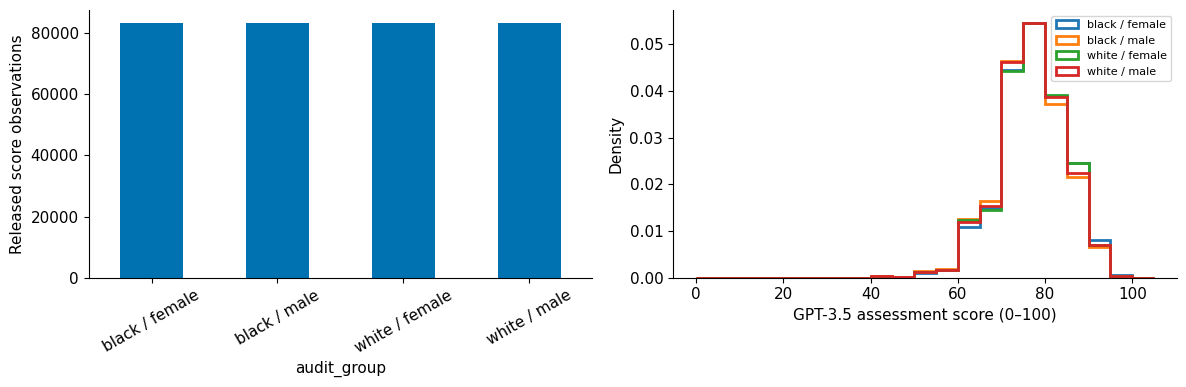

In [4]:
support=data.groupby("audit_group").score_gpt35.agg(n="size",mean="mean",median="median",sd="std")
display(support)
fig,axes=plt.subplots(1,2,figsize=(12,4))
support["n"].plot.bar(ax=axes[0],color="#0072B2");axes[0].set_ylabel("Released score observations")
for group,part in data.groupby("audit_group"):
    axes[1].hist(part.score_gpt35,bins=np.arange(0,106,5),density=True,histtype="step",linewidth=2,label=group)
axes[1].set_xlabel("GPT-3.5 assessment score (0–100)");axes[1].set_ylabel("Density");axes[1].legend(fontsize=8)
axes[0].tick_params(axis="x",rotation=30);plt.tight_layout();plt.show()

### 1.4 A descriptive gap has a named reference

For each group g, calculate mean(score | g) − mean(score | white/male). This uses two group-specific denominators. It does not compare matched pairs: the released table has no stable base-profile identifier that establishes pairs across cue conditions.

**Student task:** Compute one mean difference from the table. Is the unit score points, percentage points, or percent? Explain why no TPR can be calculated: there is no validated candidate-performance outcome label.

In [5]:
reference="white / male"
descriptive=support.copy()
descriptive["gap_vs_white_male_score_points"]=descriptive["mean"]-descriptive.loc[reference,"mean"]
display(descriptive)
display(data.groupby("gender_cue").score_gpt35.agg(n="size",mean="mean"))
display(data.groupby("race_cue").score_gpt35.agg(n="size",mean="mean"))

,n,mean,median,sd,gap_vs_white_male_score_points
audit_group,,,,,
black / female,83159,74.8511,75.0000,7.8061,0.3854
black / male,83381,74.1644,75.0000,7.9272,-0.3013
white / female,83173,74.6673,75.0000,7.8652,0.2016
white / male,83181,74.4657,75.0000,7.7954,0.0000


,n,mean
gender_cue,,
female,166332,74.7592
male,166562,74.3149


,n,mean
race_cue,,
black,166540,74.5073
white,166354,74.5665


### 1.5 Convert a score into a disclosed hypothetical decision

A score above a threshold is a **hypothetical shortlist rule**. It is not an observed hiring probability. At each threshold, selection rate is the number of complete scores at or above that threshold divided by all complete scores in that group.

The first threshold is specified in code. The sweep is exploratory sensitivity analysis, not an opportunity to pick the most dramatic result and present it as a preregistered finding. A provider score of 80 does not mean an 80% chance of job success.

,n,selected,rate,gap_vs_reference_pp
audit_group,,,,
black / female,83159,29984,0.3606,1.7275
black / male,83381,27470,0.3295,-1.3836
white / female,83173,29611,0.3560,1.2729
white / male,83181,28555,0.3433,0.0000


black / female: 29984/83159 = 36.06% at threshold 80
black / male: 27470/83381 = 32.95% at threshold 80
white / female: 29611/83173 = 35.60% at threshold 80
white / male: 28555/83181 = 34.33% at threshold 80


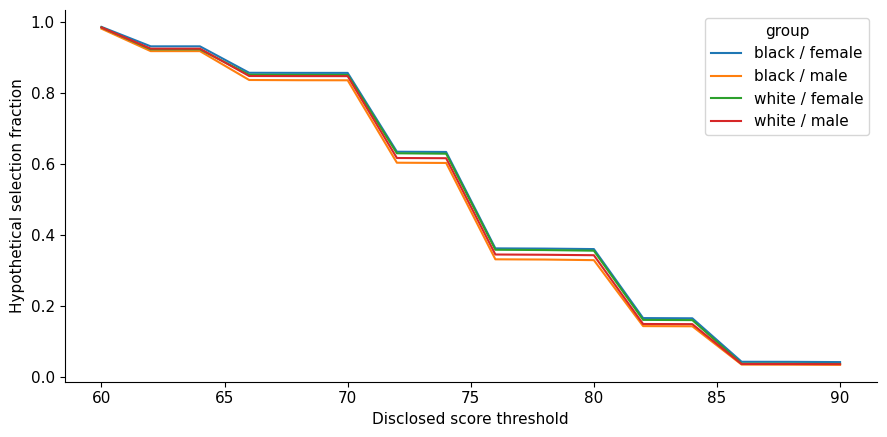

In [6]:
THRESHOLD=80
data["selected"]=data.score_gpt35.ge(THRESHOLD)
selected=data.groupby("audit_group").selected.agg(n="size",selected="sum",rate="mean")
selected["gap_vs_reference_pp"]=100*(selected.rate-selected.loc[reference,"rate"])
display(selected)
for group,row in selected.iterrows():
    print(f"{group}: {int(row.selected)}/{int(row.n)} = {row.rate:.2%} at threshold {THRESHOLD}")
sweep=[]
for threshold in range(60,91,2):
    values=data.assign(selected=data.score_gpt35.ge(threshold)).groupby("audit_group").selected.mean()
    sweep.extend({"threshold":threshold,"group":g,"rate":v} for g,v in values.items())
pd.DataFrame(sweep).pivot(index="threshold",columns="group",values="rate").plot()
plt.ylabel("Hypothetical selection fraction");plt.xlabel("Disclosed score threshold");plt.tight_layout();plt.show()

### 1.6 Check composition before attributing a mean gap

For a simple diagnostic, calculate group means **within occupation**, then average the occupation gaps equally. This changes the estimand from a pooled résumé average to an equal-occupation average. It is not the article’s controlled regression and cannot resolve all remaining differences in qualifications, state or response availability.

**Student task:** Explain why equal weighting of occupations and weighting by the number of résumés answer different questions. Which would fit an employer hiring only medical assistants?

audit_group,black / female,black / male,white / female,white / male
occupation,,,,
administrative assistant,0.6346,-0.1348,0.6107,0.0000
animal care worker,0.4678,-0.3308,-0.1700,0.0000
cashier,0.4156,-0.3220,0.6013,0.0000
dishwasher,0.3252,-0.3850,-0.0946,0.0000
food preparation worker,0.3318,-0.4500,-0.0935,0.0000


audit_group
black / female    0.3935
black / male     -0.2967
white / female    0.1759
white / male      0.0000
Name: Equal-occupation average gap (score points), dtype: float64

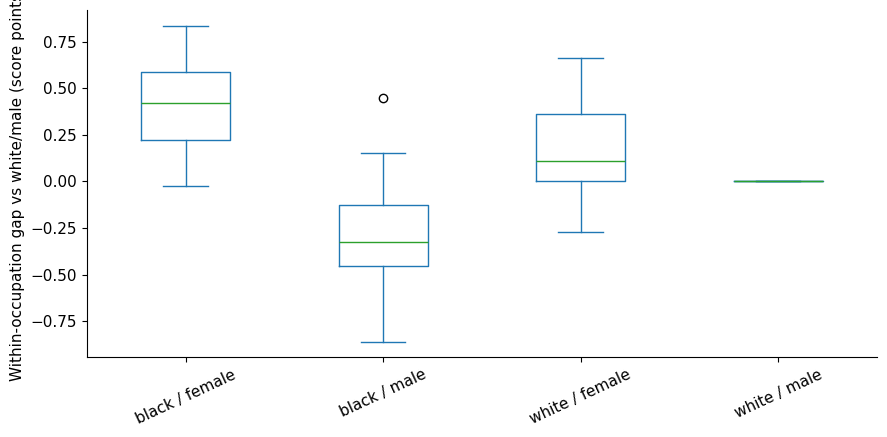

In [7]:
within=data.groupby(["occupation","audit_group"]).score_gpt35.mean().unstack()
occupation_gaps=within.subtract(within[reference],axis=0)
display(occupation_gaps.head())
display(occupation_gaps.mean().rename("Equal-occupation average gap (score points)"))
ax=occupation_gaps.plot.box(rot=25)
ax.set_ylabel("Within-occupation gap vs white/male (score points)");plt.tight_layout();plt.show()

### 1.7 Other model snapshots and response availability

The four-model file contains **332,257 rows** and model-specific missing scores. Never fill missing scores with zero. A failure to return a usable score is a separate event worth auditing, and restricting to complete scores may change group composition.

This exercise reports each model using its own available scores. If you later compare models on a common cohort, show how that restriction changes support. Do not merge the GPT-3.5 and four-model files on their local row identifiers. Cross-file pairing requires a verified identifier or matching procedure.

In [8]:
other=load_table("01_an_resume","data_score_4models.csv.gz")
columns=["score_gpt4o","score_gemini","score_claude","score_llama"]
missing=other.groupby("audit_group")[columns].agg(lambda x:x.isna().mean())
display(missing.rename_axis("Missing response fraction by group"))
means=other.groupby("audit_group")[columns].mean()
display(means.subtract(means.loc[reference],axis=1))
print("These differences are on each model's available-response cohort.")
print("Joint complete rows:",int(other[columns].notna().all(axis=1).sum()),"of",len(other))

,score_gpt4o,score_gemini,score_claude,score_llama
Missing response fraction by group,,,,
black / female,0.0389,0.0282,0.0402,0.0057
black / male,0.0379,0.0280,0.0442,0.0059
white / female,0.0393,0.0280,0.0423,0.0051
white / male,0.0376,0.0293,0.0432,0.0050


,score_gpt4o,score_gemini,score_claude,score_llama
audit_group,,,,
black / female,0.4186,0.9617,0.7364,0.9330
black / male,-0.6016,-0.2351,-0.6014,-0.0955
white / female,0.2386,0.7856,0.8487,0.4337
white / male,0.0000,0.0000,0.0000,0.0000


These differences are on each model's available-response cohort.
Joint complete rows: 295679 of 332257


### 1.8 Inspect the authors’ stored analysis results

The release also contains bootstrap estimates, threshold-effect summaries and heterogeneity variables. These are included in both raw and processed folders. A row in the bootstrap table is an estimated coefficient in a sampling round, not an applicant. A row in the magnitude table is a stored analysis result, not a fresh model response.

Use the original `Code.do` and its README to understand their derivation. Opening the code as text is safe and useful; this Python notebook does not execute Stata or promise exact published standard errors.

In [9]:
bootstrap=load_table("01_an_resume","data_bootstrap_gpt35.csv.gz")
magnitude=load_table("01_an_resume","data_magnitude_gpt35.csv.gz")
heterogeneity=load_table("01_an_resume","data_gpt35_heter.csv.gz")
display(bootstrap.groupby("gpt35_base").agg(rounds=("SamplingRound","nunique"),mean_coefficient=("b","mean")))
display(magnitude[["gpt35_base","cutoff","coeff","cilb","ciub"]].head(12))
print("Heterogeneity rows:",len(heterogeneity),"additional fields:",
      [x for x in heterogeneity if x.startswith("median_")])
project_data=data.copy()

,rounds,mean_coefficient
gpt35_base,,
Black,500,-0.0742
Female,500,0.4487
Female & Black,500,0.3804
Female & White,500,0.2257
Male & Black,500,-0.3003
Minority,500,0.0989


,gpt35_base,cutoff,coeff,cilb,ciub
0,Minority,>=60,-0.0005,-0.0020,0.0009
1,Female,>=60,0.0025,0.0016,0.0035
2,Black,>=60,-0.0011,-0.0022,0.0001
3,Female & Black,>=60,0.0010,0.0000,0.0030
4,Female & White,>=60,0.0000,-0.0020,0.0020
5,Male & Black,>=60,-0.0030,-0.0050,-0.0010
6,Minority,>=65,-0.0005,-0.0030,0.0020
7,Female,>=65,0.0060,0.0040,0.0080
8,Black,>=65,0.0006,-0.0019,0.0031
9,Female & Black,>=65,0.0070,0.0040,0.0090


Heterogeneity rows: 332895 additional fields: ['median_female_bls', 'median_black_bls']


### 1.9 Recognize issues and respond

| Evidence or limitation | Ethical issue | Practical response |
|---|---|---|
| Different cue scores at similar qualifications | Sensitivity to demographic signals | Reaudit a justified task-specific rubric; preserve controlled comparisons |
| Marginal averages hide an intersection | Some groups’ disadvantages are obscured | Report intersectional support and signed effects |
| Different missing-response rates | Exclusion or failure can be uneven | Report failure as an outcome; compare missingness policies |
| Binary gender and two race cues | Incomplete representation of identities | State coverage; design broader consented or fictional cue audits |
| No job-performance label | Score fairness does not show appropriate hiring | Validate the rubric and outcomes before evaluating error rates |
| Old model snapshots | Results may not transfer to current models | Log model version, prompts and dates for a new study |

**Student task:** Write an audit recommendation based on two calculated results. Include the sample-size discrepancy, one label limitation and an action the evidence supports. Avoid declaring a whole model “fair” from one dataset.

### What a practical response can and cannot do

The implemented checks expose score differences, occupation composition, threshold sensitivity and model-specific response availability. An equal-occupation average is a robustness diagnostic, not a fairness repair. Removing demographic columns from a spreadsheet does not remove name cues from the model's original text or reverse existing scores.

| Recognized problem | Evidence from this notebook | Concrete response | Additional evidence needed |
|---|---|---|---|
| Intersectional disparity | Compare all four cue groups and marginal averages | Audit the same deployment version with controlled cue changes | A verified pairing key or new controlled profiles |
| Threshold amplification | Selection gaps vary across cutoffs | Justify the screening rule and review borderline exclusions | Independent job-relevant assessment and accessibility checks |
| Response failures | Some models/groups have missing scores | Log failures separately and route unresolved cases to review | A prospective failure-handling audit |
| Invalid target interpretation | No independent performance `y` exists | Validate a structured rubric before using scores to select people | Consented or fictional work-sample study with documented annotation |

**Core-class output:** one support table, the threshold-80 selection calculation for two groups, one visualization and a recommendation that names missing job-performance evidence. These descriptive values differ from the paper's adjusted coefficients. Do not report one as the other.

**Worked checkpoint from the included snapshot:** black/male cue rows have 27,470/83,381 shortlisted (32.945%); white/male rows have 28,555/83,181 (34.329%). Their signed gap is −1.384 percentage points. The counts include only valid GPT-3.5 responses.

## Part 2 — Extend this into a final project

### 2.1 Choose a question and make it falsifiable

**Starting question:** How robust are intersectional résumé-score disparities to occupation composition, response availability and shortlist thresholds?

Your unit of analysis is **a generated résumé observation; cluster structure must be justified**. The suggested primary quantity is **signed score or selection gap vs a named reference**. This is a starting choice to defend, not a universal definition of fairness. Select one main question; a large collection of plots is not a research contribution.

Possible directions:

- Intersectional effects may remain after occupation standardization even when a marginal comparison is small.
- A model comparison may change when all models are restricted to common valid responses.
- A score gap may matter more near a chosen screening threshold than elsewhere.

**TODO — Before calculating new results**, write a short protocol containing: the population and decision; whose interests you prioritize; the primary metric and reference group; the sign of the comparison; one practical effect-size threshold; the split or resampling unit; the intervention; and what evidence would change your recommendation. State which assumptions can be checked with these data and which cannot.

In [10]:
PROJECT_SPEC = {
    "case_id": "C1",
    "question": "TODO: one testable question",
    "unit": 'a generated résumé observation; cluster structure must be justified',
    "primary_metric": 'signed score or selection gap vs a named reference',
    "reference_group": "TODO",
    "practical_effect_threshold": None,  # TODO: value AND unit
    "validation_plan": "TODO: prevent repeated-unit or test-set leakage",
    "intervention": "TODO",
    "ethics_and_label_assumptions": "TODO",
    "seed": SEED,
}
PROJECT_DIR = ROOT / "reports" / 'C1'
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
display(pd.Series(PROJECT_SPEC, name="Your preregistered choices"))

case_id                                                                        C1
question                                              TODO: one testable question
unit                            a generated résumé observation; cluster struct...
primary_metric                  signed score or selection gap vs a named refer...
reference_group                                                              TODO
practical_effect_threshold                                                   None
validation_plan                   TODO: prevent repeated-unit or test-set leakage
intervention                                                                 TODO
ethics_and_label_assumptions                                                 TODO
seed                                                                           42
Name: Your preregistered choices, dtype: object

### 2.2 TODO work packages, with implementation hints

1. **TODO: Reconstruct one adjusted analysis.** Use the original code to list all controls and fixed effects. Hint: original category codes are retained; dates need a documented numerical encoding. Compare a simple mean, occupation-adjusted estimate and a fuller specification.
2. **TODO: Quantify uncertainty appropriately.** Read how the source clusters errors by occupation×state. Hint: there are far fewer clusters than résumé rows; use a method suitable for the number of clusters and explain its assumptions. Do not label an ordinary row bootstrap the published cluster analysis.
3. **TODO: Investigate missingness.** Measure invalid/missing response rates by group and model. Hint: compare available-case and joint-complete analyses, plus explicit sensitivity bounds. Do not manufacture low scores for failed responses.
4. **TODO: Make one substantive extension.** Compare occupation-specific policies, an agreed screening budget or a broader controlled cue design. Hint: choose policy settings without selecting a favourable final test result.
5. **TODO: Evaluate task validity.** Design a small, consented or synthetic work-sample rubric with multiple annotators. Hint: document disagreements, time, compensation and an opt-out mechanism rather than assuming one annotator creates ground truth.

### 2.3 Protect the validity of your comparison

No stable cross-file profile key is supplied. Do not invent one. Cues are assigned signals, not verified human identity. The release is an analysis subset, not a guarantee that the entire headline résumé corpus is present. Any new external-model experiment must use appropriate data permissions and a documented version/prompt/budget; no paid calls occur here.

Keep raw files unchanged. Put project-specific derived data under `reports/C1/`, record the transformation, and retain a stable identifier for every independent unit. Fit preprocessing and models using training data. Choose thresholds, features and other settings on validation data. Use a test set once for the final comparison; if you revise after seeing it, obtain a new holdout or label the analysis exploratory. For descriptive studies without model training, predefine the comparisons and acknowledge that many subgroup/threshold searches are exploratory.

For uncertainty, resample independent units rather than rows that repeat the same person or profile. Report the number of units, the number of observations, missingness, an effect size and an interval. Document any multiple-testing strategy before interpreting a collection of p-values. A non-significant result is not proof of equivalence. If your purpose is to show effects are small, specify an equivalence margin and use an appropriate procedure.

In [11]:
def student_extension(data, spec):
    """TODO: return a dictionary with results, uncertainty, and a defensible recommendation.

    Suggested keys:
    question, independent_units, preprocessing_log, results_table,
    primary_effect, interval, harms_and_benefits, limitations, recommendation.
    Save figures/tables into PROJECT_DIR; keep evidence separate from interpretation.
    """
    raise NotImplementedError("Implement your research question; Part 1 is the starting point.")

RUN_STUDENT_PROJECT = False  # Set True only after implementing the TODO above.
if RUN_STUDENT_PROJECT:
    project_result = student_extension(project_data.copy(), PROJECT_SPEC)
    assert isinstance(project_result, dict)
    assert {"results_table", "limitations", "recommendation"}.issubset(project_result)
    display(project_result["results_table"])

### 2.4 A useful final submission

Submit the extended notebook with a clean “Restart kernel → Run all” execution, an environment file, a processing log, and a 1,500–2,500 word report. Include one baseline, one substantive extension, one uncertainty or sensitivity analysis, and one clearly stated failure or limitation. The report should answer: **What changed? Who gained or lost? What do the data support? What remains unknown? What should be done next, and by whom?**

Use the supplied project protocol, data-card and audit-report templates. Include an authorship/AI-use statement: identify assistance received, verify generated code and claims yourself, and explain at least one calculation and one design choice without relying on an AI answer. Do not submit a prose conclusion that contradicts your executed results.

| Assessment component | Weight | Evidence expected |
|---|---:|---|
| Research question and justified fairness objective | 15% | Clear decision, stakeholder, unit, and hypothesis |
| Data provenance, quality and ethical analysis | 20% | Traceable source, missingness, label limitations, concrete responses |
| Correct implementation and reproducibility | 25% | Runnable code, denominators, appropriate validation, no leakage |
| Substantive extension and uncertainty | 25% | New analysis/intervention, effect size, sensitivity and limitations |
| Interpretation and communication | 15% | Supported recommendation and honest scope |

### 2.5 Peer review and oral defence

Ask another team to reproduce one figure and one numerical result. They should identify the numerator and denominator, check which records were excluded, and challenge one causal or normative assumption. During a short oral defence, explain why your chosen metric fits the decision, demonstrate an edge case such as an empty subgroup, and name evidence that could reverse your conclusion.

**Submission checklist:** notebook runs; sources cited; no raw data silently changed; all exclusions counted; score scale and decision direction stated; TODOs addressed; results distinguish descriptive evidence from causal or legal claims; privacy and annotator work considered; final recommendation includes a monitoring or reconsideration trigger.

**Exit reflection:** Write three sentences: “Our strongest evidence is …”; “This cannot establish …”; “Our next action is …”.